In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [6]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/arjunsinghgangwar/ipl-20082026-matches-dataset/IPL_Matches_Data_2008_2026.csv


In [7]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/arjunsinghgangwar/ipl-20082026-matches-dataset/IPL_Matches_Data_2008_2026.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(1243, 31)
['event_name', 'season', 'match_number', 'date', 'city', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'team1_runs', 'team1_wickets', 'team2_runs', 'team2_wickets', 'winner', 'result_type', 'win_by_runs', 'win_by_wickets', 'player_of_match', 'match_referee', 'umpire1', 'umpire2', 'tv_umpire', 'reserve_umpire', 'match_type', 'overs_limit', 'balls_per_over', 'gender', 'team_type', 'team1_players', 'team2_players']


,event_name,season,match_number,date,city,venue,team1,team2,toss_winner,toss_decision,...,umpire2,tv_umpire,reserve_umpire,match_type,overs_limit,balls_per_over,gender,team_type,team1_players,team2_players
0,Indian Premier League,2007/08,1.0,18-04-2008,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,...,RE Koertzen,AM Saheba,VN Kulkarni,T20,20,6,male,club,"R Dravid, W Jaffer, V Kohli, JH Kallis, CL Whi...","SC Ganguly, BB McCullum, RT Ponting, DJ Hussey..."
1,Indian Premier League,2007/08,2.0,19-04-2008,Chandigarh,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,...,SL Shastri,RB Tiffin,MSS Ranawat,T20,20,6,male,club,"K Goel, JR Hopes, KC Sangakkara, Yuvraj Singh,...","PA Patel, ML Hayden, MEK Hussey, MS Dhoni, SK ..."
2,Indian Premier League,2007/08,3.0,19-04-2008,Delhi,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,...,GA Pratapkumar,IL Howell,Unknown,T20,20,6,male,club,"G Gambhir, V Sehwag, S Dhawan, MK Tiwary, KD K...","T Kohli, YK Pathan, SR Watson, M Kaif, DS Lehm..."
3,Indian Premier League,2007/08,4.0,20-04-2008,Kolkata,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,...,K Hariharan,Asad Rauf,F Gomes,T20,20,6,male,club,"WP Saha, BB McCullum, RT Ponting, SC Ganguly, ...","AC Gilchrist, Y Venugopal Rao, VVS Laxman, A S..."
4,Indian Premier League,2007/08,5.0,20-04-2008,Mumbai,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,...,DJ Harper,AV Jayaprakash,SN Bandekar,T20,20,6,male,club,"L Ronchi, ST Jayasuriya, DJ Thornely, RV Uthap...","S Chanderpaul, R Dravid, LRPL Taylor, JH Kalli..."


In [8]:
print(df.isnull().sum())
print(df['season'].unique())
print(df['team1'].unique())

event_name          0
season              0
match_number       74
date                0
city                0
venue               0
team1               0
team2               0
toss_winner         0
toss_decision       0
team1_runs          0
team1_wickets       0
team2_runs          0
team2_wickets       0
winner             25
result_type         0
win_by_runs         0
win_by_wickets      0
player_of_match     9
match_referee       0
umpire1             0
umpire2             0
tv_umpire           0
reserve_umpire      0
match_type          0
overs_limit         0
balls_per_over      0
gender              0
team_type           0
team1_players       0
team2_players       0
dtype: int64
['2007/08' '2009' '2009/10' '2011' '2012' '2013' '2014' '2015' '2016'
 '2017' '2018' '2019' '2020/21' '2021' '2022' '2023' '2024' '2025' '2026']
['Royal Challengers Bangalore' 'Kings XI Punjab' 'Delhi Daredevils'
 'Kolkata Knight Riders' 'Mumbai Indians' 'Rajasthan Royals'
 'Deccan Chargers' 'Chennai Sup

In [9]:
print(df['team1'].unique())

['Royal Challengers Bangalore' 'Kings XI Punjab' 'Delhi Daredevils'
 'Kolkata Knight Riders' 'Mumbai Indians' 'Rajasthan Royals'
 'Deccan Chargers' 'Chennai Super Kings' 'Kochi Tuskers Kerala'
 'Pune Warriors' 'Sunrisers Hyderabad' 'Gujarat Lions'
 'Rising Pune Supergiants' 'Rising Pune Supergiant' 'Delhi Capitals'
 'Punjab Kings' 'Lucknow Super Giants' 'Gujarat Titans'
 'Royal Challengers Bengaluru']


In [29]:
team_map = {
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru',
    'Kings XI Punjab': 'Punjab Kings',
    'Delhi Daredevils': 'Delhi Capitals',
    'Rising Pune Supergiants': 'Rising Pune Supergiant'
}

for col in ['team1', 'team2', 'toss_winner', 'winner']:
    df[col] = df[col].replace(team_map)

print(df['team1'].unique())

['Royal Challengers Bengaluru' 'Punjab Kings' 'Delhi Capitals'
 'Kolkata Knight Riders' 'Mumbai Indians' 'Rajasthan Royals'
 'Deccan Chargers' 'Chennai Super Kings' 'Kochi Tuskers Kerala'
 'Pune Warriors' 'Sunrisers Hyderabad' 'Gujarat Lions'
 'Rising Pune Supergiant' 'Lucknow Super Giants' 'Gujarat Titans']


In [20]:
team_map = {
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru',
    'Kings XI Punjab': 'Punjab Kings',
    'Delhi Daredevils': 'Delhi Capitals',
    'Rising Pune Supergiants': 'Rising Pune Supergiant'
}

season_map={'2007/08': '2008', '2009/10': '2010', '2020/21': '2020'}
df['season_year']=df['season'].replace(season_map).astype(int)

print(sorted(df['season_year'].unique()))

[np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


In [25]:
df['match_date']= pd.to_datetime(df['date'], format='%d-%m-%Y')
print(df[['date', 'match_date']].head(3))
print(df['match_date'].dtype)

         date match_date
0  18-04-2008 2008-04-18
1  19-04-2008 2008-04-19
2  19-04-2008 2008-04-19
datetime64[ns]


In [1]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/arjunsinghgangwar/ipl-20082026-matches-dataset/IPL_Matches_Data_2008_2026.csv")

team_map = {
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru',
    'Kings XI Punjab': 'Punjab Kings',
    'Delhi Daredevils': 'Delhi Capitals',
    'Rising Pune Supergiants': 'Rising Pune Supergiant'
}
for col in ['team1', 'team2', 'toss_winner', 'winner']:
    df[col] = df[col].replace(team_map)

season_map = {'2007/08': '2008', '2009/10': '2010', '2020/21': '2020'}
df['season_year'] = df['season'].replace(season_map).astype(int)

df['match_date'] = pd.to_datetime(df['date'], format='%d-%m-%Y')

print(df.shape)

(1243, 33)


In [2]:
print(df['result_type'].value_counts())
print(df[df['winner'].isnull()][['match_date', 'team1', 'team2', 'result_type']].head())

result_type
complete     1218
tie            16
no result       9
Name: count, dtype: int64
    match_date                        team1                        team2  \
66  2009-04-23        Kolkata Knight Riders             Rajasthan Royals   
130 2010-03-21          Chennai Super Kings                 Punjab Kings   
241 2011-05-21               Delhi Capitals                Pune Warriors   
328 2013-04-07          Sunrisers Hyderabad  Royal Challengers Bengaluru   
342 2013-04-16  Royal Challengers Bengaluru               Delhi Capitals   

    result_type  
66          tie  
130         tie  
241   no result  
328         tie  
342         tie  


In [5]:
df_win = df[df['result_type'] == 'complete']
print(df_win.shape)
print(df_win['winner'].value_counts().head(5))

(1218, 33)
winner
Mumbai Indians                 155
Chennai Super Kings            148
Royal Challengers Bengaluru    143
Kolkata Knight Riders          140
Punjab Kings                   126
Name: count, dtype: int64


In [4]:
df_win=df[df['result_type']=='complete']
print(df_win.shape)
print(df_win['player_of_match'].value_counts().head(5))

(1218, 33)
player_of_match
AB de Villiers    24
CH Gayle          22
RG Sharma         21
V Kohli           21
DA Warner         18
Name: count, dtype: int64


In [8]:
print((df_win['toss_winner']==df_win['winner']).sum())
print((df_win['toss_winner']==df_win['winner']).mean(),*100)



628
51.55993431855501


In [21]:
df_win = df[df['result_type'] == 'complete'].copy()
df_win['toss_won_match']=df_win['toss_winner']==df_win['winner']
print(df_win.groupby('toss_decision')['toss_won_match'].mean()*100)
print(df_win['toss_decision'].value_counts())



toss_decision
bat      45.343137
field    54.691358
Name: toss_won_match, dtype: float64
toss_decision
field    810
bat      408
Name: count, dtype: int64


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/kaggle/input/datasets/arjunsinghgangwar/ipl-20082026-matches-dataset/IPL_Matches_Data_2008_2026.csv")

team_map = {
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru',
    'Kings XI Punjab': 'Punjab Kings',
    'Delhi Daredevils': 'Delhi Capitals',
    'Rising Pune Supergiants': 'Rising Pune Supergiant'
}
for col in ['team1', 'team2', 'toss_winner', 'winner']:
    df[col] = df[col].replace(team_map)

season_map = {'2007/08': '2008', '2009/10': '2010', '2020/21': '2020'}
df['season_year'] = df['season'].replace(season_map).astype(int)

df['match_date'] = pd.to_datetime(df['date'], format='%d-%m-%Y')

df_win = df[df['result_type'] == 'complete'].copy()
print(df.shape, df_win.shape)

(1243, 33) (1218, 33)


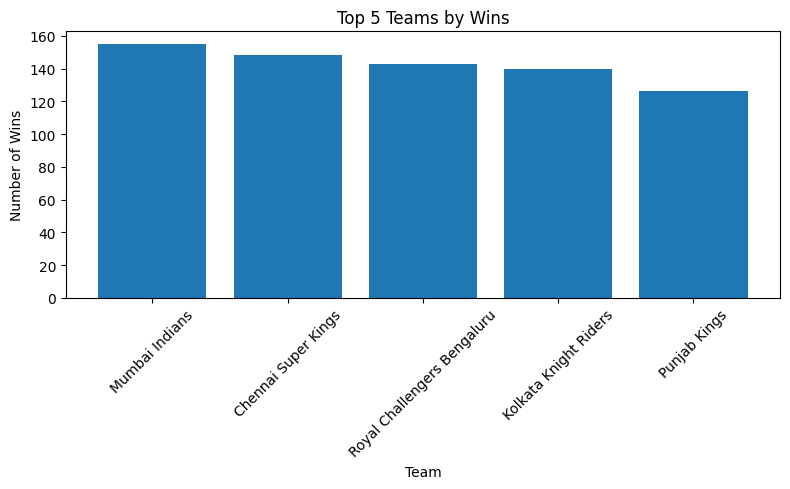

In [5]:
import matplotlib.pyplot as plt

top5 = df_win['winner'].value_counts().head(5)

plt.figure(figsize=(8, 5))
plt.bar(top5.index, top5.values)
plt.title('Top 5 Teams by Wins')
plt.xlabel('Team')
plt.ylabel('Number of Wins')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

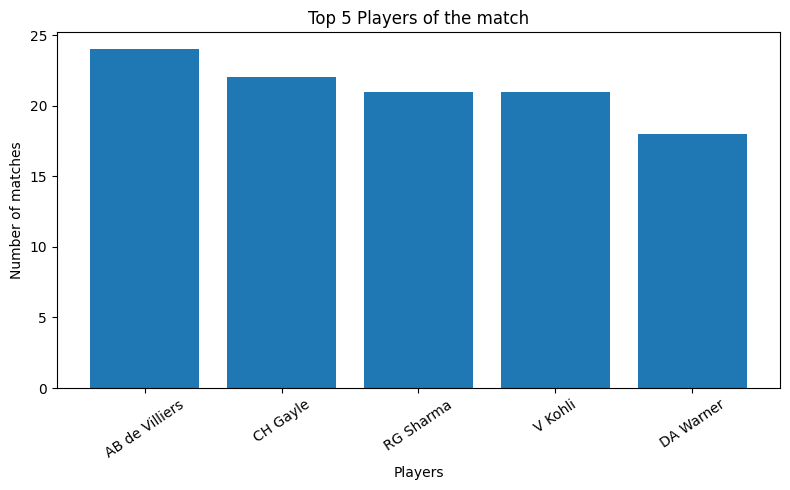

In [13]:
import matplotlib.pyplot as plt
top5_players=df_win['player_of_match'].value_counts().head(5)

plt.figure(figsize=(8,5))
plt.bar(top5.index,top5.values)
plt.title('Top 5 Players of the match')
plt.xlabel('Players')
plt.ylabel('Number of matches')
plt.xticks(rotation=34)
plt.tight_layout()
plt.show()

In [24]:
import importlib
importlib.reload(plt)

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

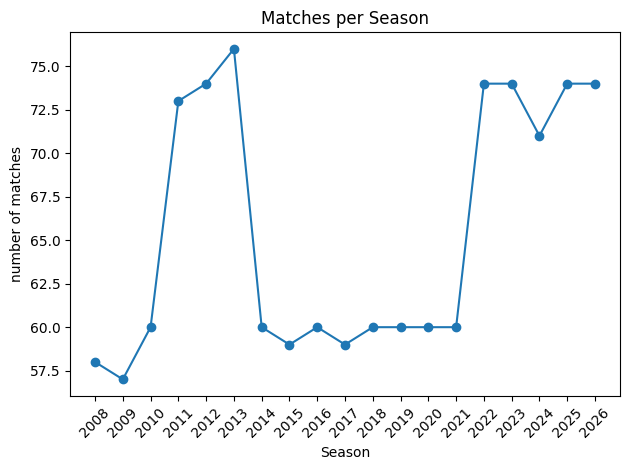

In [25]:
import matplotlib.pyplot as plt
plt.plot(season_matches.index,season_matches.values,marker='o')
plt.title('Matches per Season')
plt.xlabel('Season')
plt.ylabel('number of matches')
plt.xticks(season_matches.index,rotation=45)
plt.tight_layout()
plt.show()

In [2]:
top5_venues = df['venue'].value_counts().head(5)
print(top5_venues)

venue
Eden Gardens                77
Wankhede Stadium            73
M Chinnaswamy Stadium       65
Feroz Shah Kotla            60
Wankhede Stadium, Mumbai    59
Name: count, dtype: int64


In [11]:
top5_cities = df['city'].value_counts().head(5)
print(top5_cities)

city
Mumbai       187
Kolkata      107
Delhi        104
Chennai       98
Hyderabad     90
Name: count, dtype: int64


In [22]:
df['venue_clean'] = df['venue'].str.split(',').str[0]
print(df['venue_clean'].value_counts().head(5))

venue_clean
Wankhede Stadium                      132
Eden Gardens                          107
MA Chidambaram Stadium                 98
Rajiv Gandhi International Stadium     90
M Chinnaswamy Stadium                  89
Name: count, dtype: int64


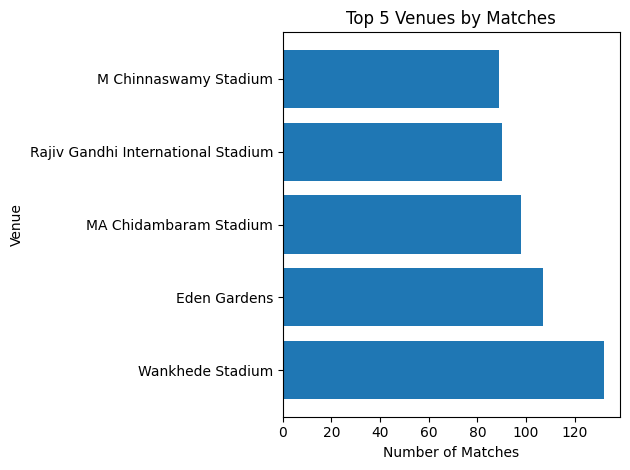

In [24]:
top5_venues = df['venue_clean'].value_counts().head(5)


plt.barh(top5_venues.index, top5_venues.values)
plt.title('Top 5 Venues by Matches')
plt.xlabel('Number of Matches')
plt.ylabel('Venue')
plt.tight_layout()
plt.show()

In [25]:
print(df['city'].value_counts())

city
Mumbai            187
Kolkata           107
Delhi             104
Chennai            98
Hyderabad          90
Jaipur             68
Bangalore          65
Chandigarh         61
Ahmedabad          53
Pune               51
Unknown            51
Bengaluru          39
Abu Dhabi          37
Lucknow            29
Dharamsala         19
Visakhapatnam      17
Durban             15
Dubai              13
Centurion          12
Rajkot             10
Sharjah            10
Indore              9
Mohali              9
Navi Mumbai         9
Johannesburg        8
Raipur              8
Guwahati            8
New Chandigarh      8
Port Elizabeth      7
Cape Town           7
Ranchi              7
Cuttack             7
Kochi               5
Kanpur              4
Kimberley           3
Nagpur              3
East London         3
Bloemfontein        2
Name: count, dtype: int64


In [26]:
df['city'] = df['city'].replace('Bangalore', 'Bengaluru')
print(df['city'].value_counts().head(8))

city
Mumbai        187
Kolkata       107
Bengaluru     104
Delhi         104
Chennai        98
Hyderabad      90
Jaipur         68
Chandigarh     61
Name: count, dtype: int64


In [28]:


df_clean = df.drop(columns=['event_name', 'gender', 'team_type', 'balls_per_over', 'umpire1', 'umpire2', 'tv_umpire', 'reserve_umpire', 'match_referee', 'team1_players', 'team2_players'])
df_clean.to_csv('/kaggle/working/ipl_matches_clean.csv', index=False)
print(df_clean.shape)

(1243, 23)
